# Phase 5 LSTM forecasts and strategy comparison

I use the two exploratory pairs carried forward from Phase 3. The model predicts five changes from the current Z-score; adding each change to the observed Z gives its forecast level. I compare forecast error with persistence and use the day-five direction to filter statistical entries.

Model selection uses 2018-2023 targets and 2024-2025 validation. The earlier OLS and normalization are fitted again for that split. The shortlist was selected through 2025, so this validation is conditional on it. The final fit uses the saved full-history OLS and Phase 4 normalization. The 2026 interval has already been examined in Phase 4; it is held out from this model's fitting, rather than a newly untouched test.


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display, Image
from market_analytics.models.forecasting import run_lstm_forecast, historical_handoff, load_config, forecast_from_prices
from market_analytics.features.sequences import fit_selection_spread, build_features, build_sequences
from market_analytics.trading.baseline import spread_from_prices, apply_normalization
root = Path.cwd()
if not (root / "configs").exists():
    root = root.parent
config = root / "configs/lstm_forecast.json"
_, cfg = load_config(config)
handoff, baseline, norms = historical_handoff(root, cfg)
metrics = root / "outputs/metrics/lstm" / cfg["model_version"]


## Feature and date checks

The five inputs are Z, its first three lags, and its trailing 20-session sample standard deviation. A sequence contains 20 feature rows. The rolling statistic needs earlier observations too, so the first usable origin is the 39th spread observation. Training targets stop before validation begins; known earlier feature rows remain available as context.


In [2]:
window_rows = []
for pair in handoff["parameters"]:
    ols, norm = fit_selection_spread(handoff["prices"], pair)
    z = apply_normalization(spread_from_prices(handoff["prices"], ols), norm)
    features = build_features(z)
    train = build_sequences(features, z, "2018-01-01", "2023-12-31")
    validation = build_sequences(features, z, "2024-01-01", "2025-12-31")
    assert len(train["X"]) == 1466 and len(validation["X"]) == 498
    assert train["index"].target_h5.max() < validation["index"].target_h1.min()
    window_rows.append({"pair": pair["pair_id"], "selection_beta": ols["beta"],
                        "resting_z": norm["resting_z"], "train_samples": len(train["X"]),
                        "validation_samples": len(validation["X"]),
                        "last_training_target": train["index"].target_h5.max()})
display(pd.DataFrame(window_rows))
display(train["index"].tail(2))
display(validation["index"].head(2))


,pair,selection_beta,resting_z,train_samples,validation_samples,last_training_target
0,AMZN_META,0.726523,1.066348,1466,498,2023-12-29
1,NVDA_AMZN,0.252268,2.784342,1466,498,2023-12-29


,input_start,input_end,origin,origin_z,target_h1,target_h2,target_h3,target_h4,target_h5
1464,2023-11-22,2023-12-20,2023-12-20,1.852566,2023-12-21,2023-12-22,2023-12-26,2023-12-27,2023-12-28
1465,2023-11-24,2023-12-21,2023-12-21,1.931812,2023-12-22,2023-12-26,2023-12-27,2023-12-28,2023-12-29


,input_start,input_end,origin,origin_z,target_h1,target_h2,target_h3,target_h4,target_h5
0,2023-12-01,2023-12-29,2023-12-29,1.751954,2024-01-02,2024-01-03,2024-01-04,2024-01-05,2024-01-08
1,2023-12-04,2024-01-02,2024-01-02,1.676889,2024-01-03,2024-01-04,2024-01-05,2024-01-08,2024-01-09


## Historical selection and final evaluation

Four configurations are compared by pooled validation RMSE for each pair. Seeds 7 and 2026 describe sensitivity after choosing the seed-42 design. They do not select a replacement model. The final network starts from fresh weights and uses the selected epoch count. Every trial and its losses are saved.

The runner freezes a contract before reading the unseen master. In the comparison, both accounts start flat and use the same entry calendar, capital, costs, next-open execution, and final close marks. Observed-Z exits continue after the last origin with a full five-day target.


In [3]:
results = run_lstm_forecast(config)
selection = json.loads((metrics / "selection.json").read_text())
display(pd.read_csv(metrics / "trials.csv"))


Selection AMZN_META h16_lr0.001_s42


Selection AMZN_META h16_lr0.0003_s42


Selection AMZN_META h32_lr0.001_s42


Selection AMZN_META h32_lr0.0003_s42


Sensitivity AMZN_META seed 7


Sensitivity AMZN_META seed 2026


... (5 outputs left out)

Sensitivity NVDA_AMZN seed 2026


Refit AMZN_META epochs 22


Refit NVDA_AMZN epochs 29


,seed,batch_size,max_epochs,patience,min_delta,gradient_clip,shuffle,hidden_size,learning_rate,pair_id,trial_id,rmse,best_epoch,epochs_run,role
0,42,64,200,20,0.000001,1,True,16,0.0010,AMZN_META,h16_lr0.001_s42,0.407688,2,22,candidate
1,42,64,200,20,0.000001,1,True,16,0.0003,AMZN_META,h16_lr0.0003_s42,0.407396,8,28,candidate
2,42,64,200,20,0.000001,1,True,32,0.0010,AMZN_META,h32_lr0.001_s42,0.406094,22,42,candidate
3,42,64,200,20,0.000001,1,True,32,0.0003,AMZN_META,h32_lr0.0003_s42,0.408457,8,28,candidate
4,7,64,200,20,0.000001,1,True,32,0.0010,AMZN_META,h32_lr0.001_s7,0.405855,1,21,sensitivity
5,2026,64,200,20,0.000001,1,True,32,0.0010,AMZN_META,h32_lr0.001_s2026,0.400833,35,55,sensitivity
6,42,64,200,20,0.000001,1,True,16,0.0010,NVDA_AMZN,h16_lr0.001_s42,0.334529,29,49,candidate
7,42,64,200,20,0.000001,1,True,16,0.0003,NVDA_AMZN,h16_lr0.0003_s42,0.332655,120,140,candidate
8,42,64,200,20,0.000001,1,True,32,0.0010,NVDA_AMZN,h32_lr0.001_s42,0.330322,29,49,candidate
9,42,64,200,20,0.000001,1,True,32,0.0003,NVDA_AMZN,h32_lr0.0003_s42,0.331280,77,97,candidate


## Validation trading and direction checks

The selection stage also runs both strategies on 2024-2025, using the earlier-fit spread and its beta. These runs describe the fixed filter; they did not choose anything. The direction table adds the accuracy of three rules with no model on the same origins: the more common realized sign, a move toward the fitted-period resting level, and a move toward zero.

In [4]:
validation = pd.read_csv(metrics / "strategy_comparison.csv")
display(validation[["pair_id", "strategy", "executed_entries", "closed_trades", "open_trades", "net_return", "filter_rejections"]])
agreement = pd.read_csv(metrics / "seed_agreement.csv")
display(agreement[["pair_id", "trial_id", "subset", "origins", "direction_accuracy", "acceptance_agreement_with_seed42",
                   "majority_sign_rate", "toward_resting_rate", "toward_zero_rate", "predicted_rise_share"]])
decisions = pd.read_csv(metrics / "filter_decisions.csv")
display(decisions[["pair_id", "Date", "direction", "zscore", "predicted_change_h5", "resting_z", "entry_accepted", "actual_z_h5"]])

,pair_id,strategy,executed_entries,closed_trades,open_trades,net_return,filter_rejections
0,AMZN_META,baseline_matched,2,2,0,0.274532,0
1,AMZN_META,lstm_filtered,2,2,0,0.274532,0
2,NVDA_AMZN,baseline_matched,1,0,1,0.064280,0
3,NVDA_AMZN,lstm_filtered,1,0,1,-0.027534,7


,pair_id,trial_id,subset,origins,direction_accuracy,acceptance_agreement_with_seed42,majority_sign_rate,toward_resting_rate,toward_zero_rate,predicted_rise_share
0,AMZN_META,h32_lr0.001_s42,all,498,0.536145,1.000000,0.516064,0.483936,0.530120,0.791165
1,AMZN_META,h32_lr0.001_s42,crossings,22,0.681818,1.000000,0.681818,0.681818,0.681818,1.000000
2,AMZN_META,h32_lr0.001_s7,all,498,0.497992,0.765060,0.516064,0.483936,0.530120,0.969880
3,AMZN_META,h32_lr0.001_s7,crossings,22,0.681818,1.000000,0.681818,0.681818,0.681818,1.000000
4,AMZN_META,h32_lr0.001_s2026,all,498,0.526104,0.829317,0.516064,0.483936,0.530120,0.881526
5,AMZN_META,h32_lr0.001_s2026,crossings,22,0.681818,1.000000,0.681818,0.681818,0.681818,1.000000
6,NVDA_AMZN,h32_lr0.001_s42,all,498,0.624498,1.000000,0.508032,0.594378,0.491968,0.566265
7,NVDA_AMZN,h32_lr0.001_s42,crossings,15,0.666667,1.000000,0.666667,0.666667,0.333333,0.733333
8,NVDA_AMZN,h32_lr0.001_s7,all,498,0.626506,0.857430,0.508032,0.594378,0.491968,0.652610
9,NVDA_AMZN,h32_lr0.001_s7,crossings,15,0.733333,0.800000,0.666667,0.666667,0.333333,0.800000


,pair_id,Date,direction,zscore,predicted_change_h5,resting_z,entry_accepted,actual_z_h5
0,AMZN_META,2024-08-05,long,-2.207450,0.057721,1.066348,True,-2.525269
1,AMZN_META,2025-03-03,long,-2.084165,0.180325,1.066348,True,-1.899839
2,NVDA_AMZN,2024-02-02,short,2.343470,0.082642,2.784342,False,2.265649
3,NVDA_AMZN,2024-02-21,short,2.060090,0.041432,2.784342,False,1.956354
4,NVDA_AMZN,2024-02-29,short,2.145250,0.067280,2.784342,False,1.675646
5,NVDA_AMZN,2024-04-01,short,2.026481,0.076375,2.784342,False,2.409098
6,NVDA_AMZN,2024-04-26,short,2.025978,0.049730,2.784342,False,2.417921
7,NVDA_AMZN,2024-05-01,short,2.149590,0.052561,2.784342,False,2.477239
8,NVDA_AMZN,2024-06-27,short,2.137693,0.074890,2.784342,False,2.221877
9,NVDA_AMZN,2024-07-01,short,2.091153,-0.002010,2.784342,True,2.053393


In [5]:
errors = pd.read_csv(metrics / "unseen_forecast_metrics.csv")
comparison = pd.read_csv(metrics / "unseen_strategy_comparison.csv")
display(errors.loc[errors.horizon.eq("pooled"), ["pair_id", "model", "mae", "rmse", "rmse_improvement", "origins"]])
display(pd.read_csv(metrics / "unseen_filter_decisions.csv")[["pair_id", "Date", "direction", "zscore", "forecast_z_h5", "predicted_change_h5", "entry_accepted", "actual_z_h5", "direction_correct"]])
display(comparison[["pair_id", "strategy", "executed_entries", "closed_trades", "open_trades", "win_rate", "net_return", "total_costs"]])


,pair_id,model,mae,rmse,rmse_improvement,origins
10,AMZN_META,lstm,0.394595,0.575604,-0.068477,141
11,AMZN_META,persistence,0.376237,0.538715,0.000000,141
22,NVDA_AMZN,lstm,0.516850,0.710382,-0.031650,141
23,NVDA_AMZN,persistence,0.493530,0.688589,0.000000,141


,pair_id,Date,direction,zscore,forecast_z_h5,predicted_change_h5,entry_accepted,actual_z_h5,direction_correct
0,AMZN_META,2026-01-07,short,2.023025,1.755792,-0.267234,True,2.202635,0.0
1,AMZN_META,2026-04-10,short,2.095445,1.821471,-0.273974,True,2.036748,1.0
2,NVDA_AMZN,2026-02-11,long,-2.180773,-2.401470,-0.220697,False,-2.058400,0.0
3,NVDA_AMZN,2026-02-23,long,-2.107246,-1.643695,0.463551,True,-1.607558,1.0
4,NVDA_AMZN,2026-04-24,short,2.224299,1.555933,-0.668365,True,2.741012,0.0
5,NVDA_AMZN,2026-07-31,short,2.919464,NaN,NaN,False,NaN,NaN


,pair_id,strategy,executed_entries,closed_trades,open_trades,win_rate,net_return,total_costs
0,AMZN_META,baseline_matched,2,1,1,1,-0.036917,14.604441
1,AMZN_META,lstm_filtered,2,1,1,1,-0.036917,14.604441
2,NVDA_AMZN,baseline_matched,2,2,0,1,0.218317,20.058374
3,NVDA_AMZN,lstm_filtered,2,2,0,1,0.210000,20.031613
4,AMZN_META,baseline_full_period,2,1,1,1,-0.036917,14.604441
5,NVDA_AMZN,baseline_full_period,2,2,0,1,0.218317,20.058374


## Saved model reload

Each final directory contains weights and the fitted transformations needed for inference. This check supplies dated prices ending at a historical origin and reproduces its five saved forecasts without targets or training.


In [6]:
for pair in handoff["parameters"]:
    bundle = root / "artifacts/lstm" / cfg["model_version"] / pair["pair_id"] / "final_20180102_20251231"
    example = json.loads((bundle / "known_inference.json").read_text())
    prices = pd.DataFrame(example["prices"])
    prices["Date"] = pd.to_datetime(prices["Date"])
    forecasts = forecast_from_prices(prices.set_index("Date"), bundle)
    np.testing.assert_allclose(forecasts, example["forecast_z"], **cfg["inference_tolerance"])
    print(pair["pair_id"], "reload agrees", forecasts)


AMZN_META reload agrees [1.1683811  1.21470758 1.22928023 1.28357394 1.29386684]
NVDA_AMZN reload agrees [0.23380483 0.23918442 0.22789078 0.23613538 0.22614594]


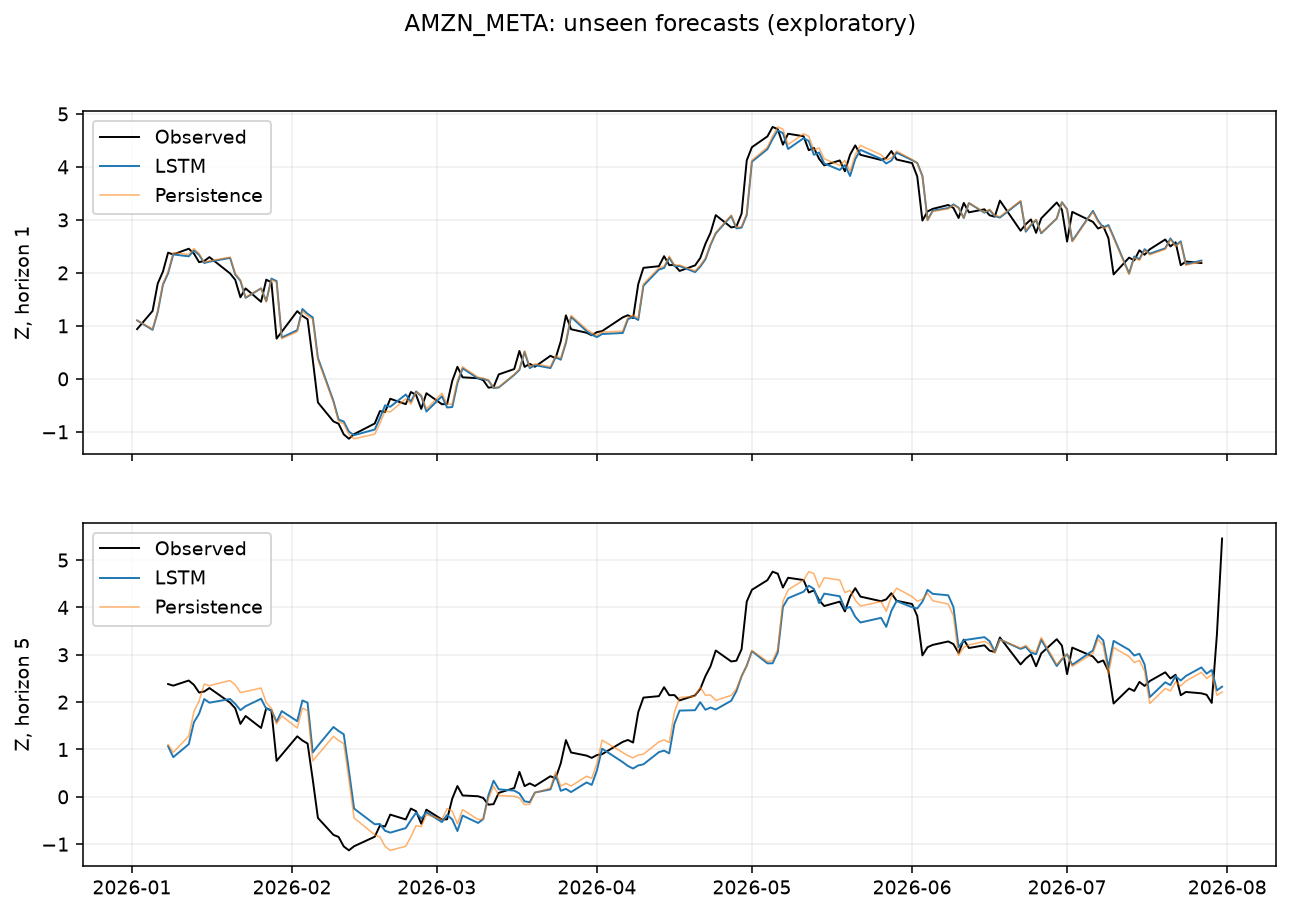

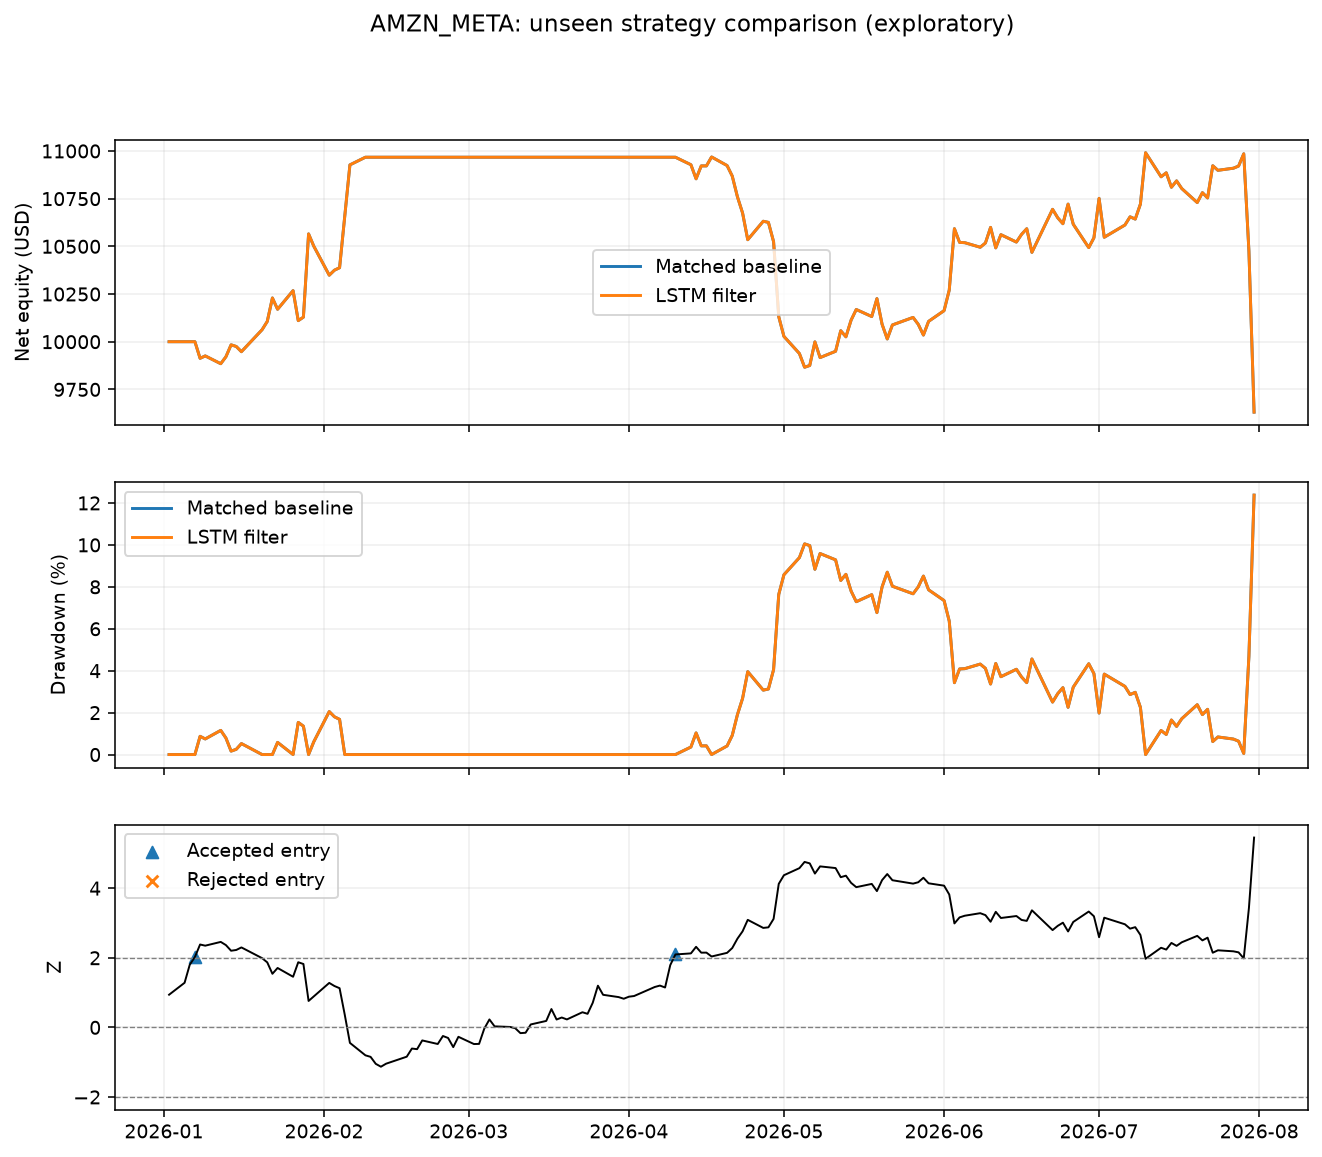

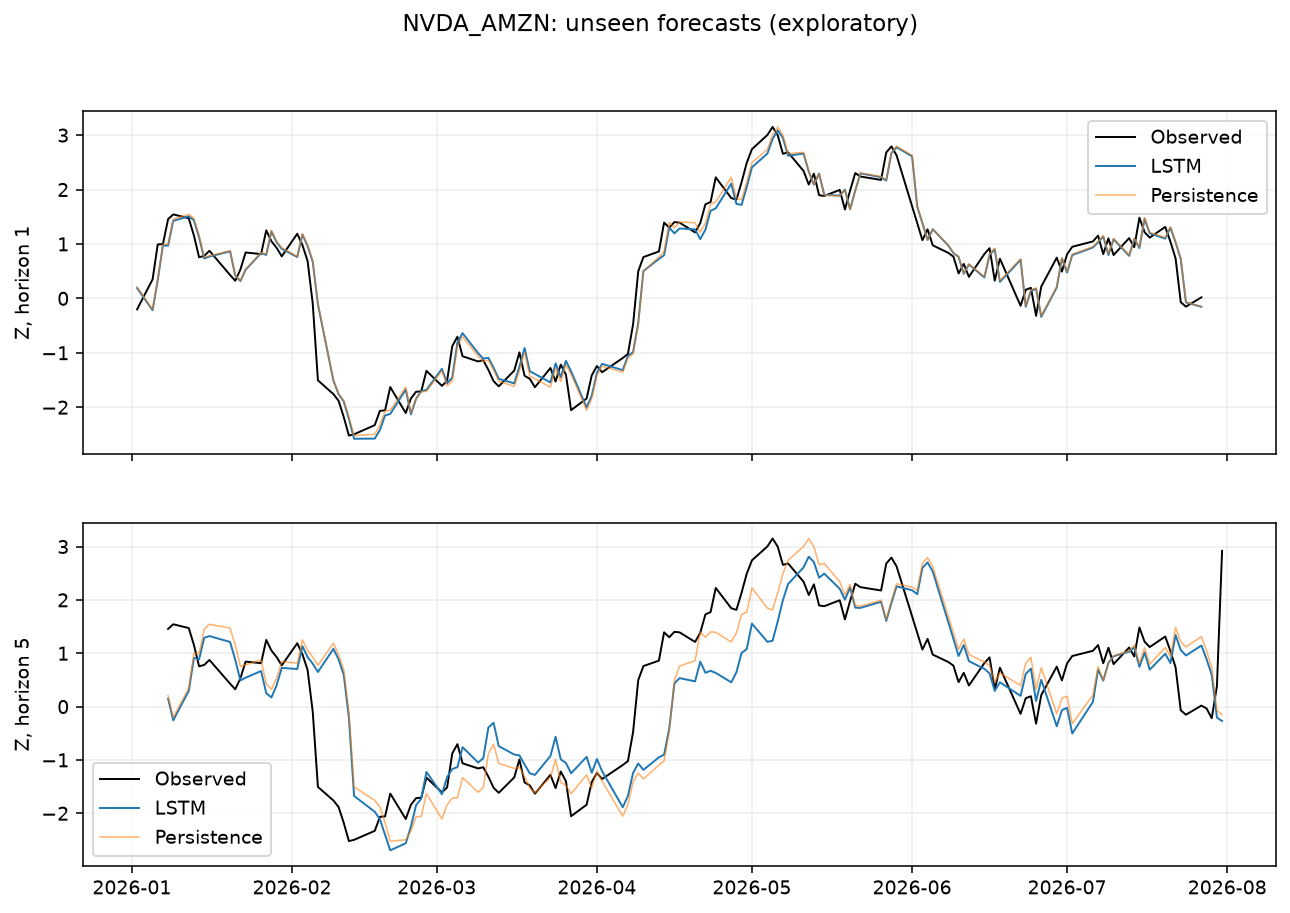

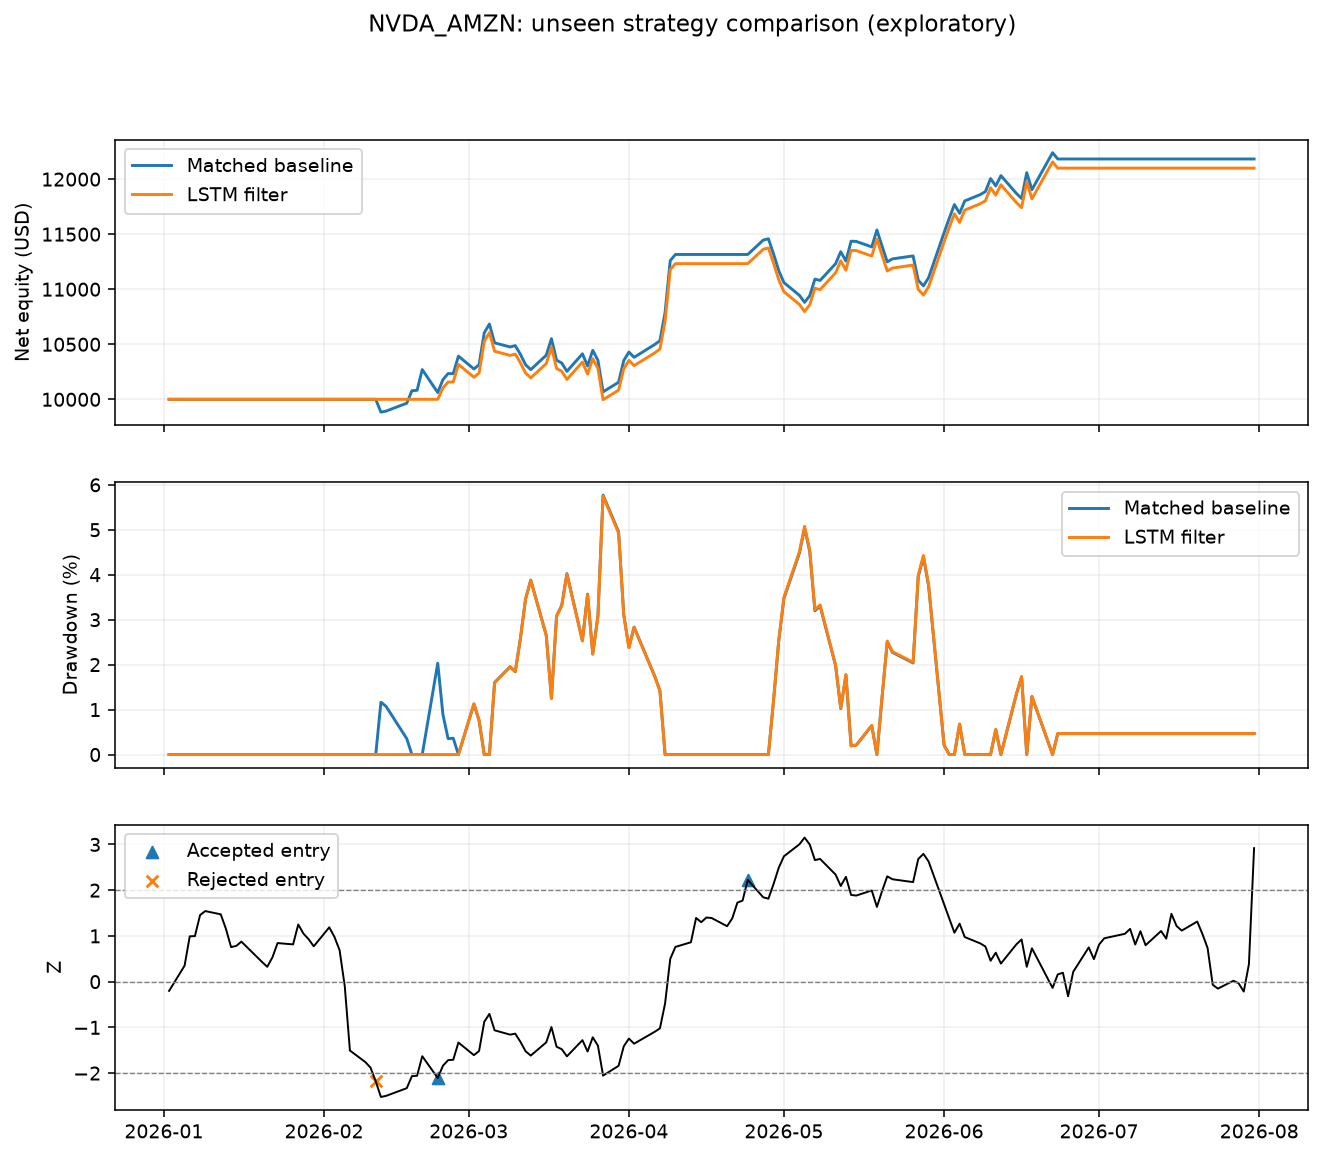

In [7]:
for pair in handoff["parameters"]:
    for suffix in ["forecasts", "strategy"]:
        display(Image(filename=str(root / "outputs/figures/lstm" / cfg["model_version"] / "unseen" / f"{pair['pair_id']}_{suffix}.png")))


The tables and figures above keep forecasting performance separate from trading outcomes. The fitted-period resting level differs from Z = 0 because normalization uses the final year. That matters when interpreting the filter, especially for the selection-stage AMZN-on-NVDA spread. The saved direction and seed-agreement tables show how stable the entry decisions are.

Findings and limitations are recorded in `docs/phase_planning/phase_5_analysis.md`; commands and fitted-object dates are saved with the run. The two pairs share AMZN and remain exploratory.
